# Choosing an angle reading: an embryo inside its eggshell

In a 4-cell *C. elegans* embryo inside its eggshell, the cells are compressed against the shell. The shell's contact forces act on the cells where they touch it, so an interface's curvature follows Laplace's law, and its tangent obeys Young–Dupré, only close to the junctions; further along, the interface takes the shape the shell imposes. For such compressed cells this example:

* reads the junction angles with the **chord** (`angle_reading="chord"`), which uses only each interface's first edge at the junction, and shows `"fitted_tangent"`, the other reading local to the junctions, as a check;
* computes **no pressures**: Laplace's law would read curvatures set by the shell, and the pressures would not make sense;
* shows the arc reading (the 2D default) and the opt-in global fit **only to explain why they are not used** here: both fit circles to the whole interfaces;
* draws the **deviatoric stress**, the contribution of the cortical tensions to each cell's stress anisotropy; under confinement the shell's contact forces also act on the cells and are not in it, so it is not the cell's total stress anisotropy.

Every comparison below is measured on one embryo per condition (one inside its eggshell, one whose eggshell was removed, three frames each): it shows which assumption fails inside the eggshell, not how accurate any reading is.

Everything 2D in foambryo is provisional. If you use foambryo, in 2D as in 3D, please cite both articles: Ichbiah S., Delbary F., McDougall A., Dumollard R., Turlier H. *Embryo mechanics cartography: inference of 3D force atlases from fluorescence microscopy.* Nature Methods 20(12), 1989–1999 (2023), doi:10.1038/s41592-023-02084-7; and Yamamoto K., Ichbiah S., Perez M., Borrego-Pinto J., Delbary F., Goehring N. W., Northrop P., Turlier H., Charras G. Spatiotemporal mapping of the contractile and adhesive forces sculpting early *C. elegans* embryos. *Developmental Cell* 61(6), 1273–1288.e4 (2026). doi:10.1016/j.devcel.2026.04.013.

**Data.** Three frames each of embryo 190429-2 (inside its eggshell) and embryo 190430-9 (eggshell removed) of the Developmental Cell 2026 article's public data (Zenodo, doi:10.5281/zenodo.19627642), CC BY-SA 4.0, in `Examples/data/`. Cells: ABa, ABp, EMS and P2 inside the eggshell; ABx1, ABx2, EMS and P2 without it.

**Needs** `pip install "foambryo[viewing]"` and a display for the viewer's figure. Run it from the `Examples/` folder; it takes a few seconds.

In [1]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

import foambryo
from foambryo.plotting_utilities import planar_mesh_drawing
from foambryo.viewing import plot_force_inference

FIGURES = Path(tempfile.mkdtemp(prefix="foambryo-2d-example-"))  # the viewer's figures are written here


def name_of(pair, names):
    """'EMS|P2' for the interface (1, 4); the medium is label 0."""
    return f"{names[pair[0]]}|{names[pair[1]]}"


def show_mask(ax, image, mesh, names, title):
    """The membrane image, the mesh's interfaces over it and each cell's name at its area centroid."""
    drawing = planar_mesh_drawing(mesh)
    ax.imshow(image, cmap="gray")
    for v1, v2 in drawing.segments[~drawing.border]:
        (r1, c1), (r2, c2) = drawing.points[v1], drawing.points[v2]
        ax.plot([c1, c2], [r1, r2], color="yellow", lw=0.8)
    for cell in drawing.cells:
        r, c = drawing.centroids[cell]
        ax.text(c, r, names[cell], color="white", ha="center", va="center", fontsize=9, weight="bold")
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()


inside the eggshell: {0: 'medium', 1: 'EMS', 2: 'ABa', 3: 'ABp', 4: 'P2'} | frame 1 normalised time 0.491525


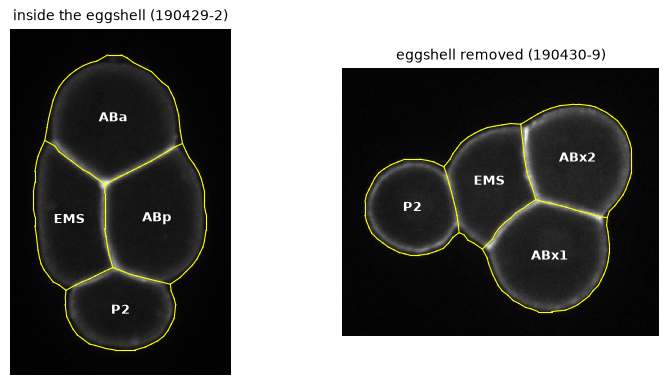

In [2]:
confined = np.load("data/c_elegans_4_cell_with_eggshell.npz")
free = np.load("data/c_elegans_4_cell_without_eggshell.npz")
names = [str(n) for n in confined["cell_names"]]
free_names = [str(n) for n in free["cell_names"]]
frame = 1  # normalised time closest to 0.5
mask, image = confined["masks"][frame], confined["images"][frame]
mesh = foambryo.dcel_mesh_from_segmentation_mask(mask)  # in pixels
print("inside the eggshell:", dict(enumerate(names)), "| frame", frame, "normalised time", confined["normalised_times"][frame])

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
show_mask(axes[0], image, mesh, names, "inside the eggshell (190429-2)")
show_mask(axes[1], free["images"][frame], foambryo.dcel_mesh_from_segmentation_mask(free["masks"][frame]), free_names, "eggshell removed (190430-9)")
plt.show()

## The tensions, read with the chord

Young's law at a junction needs only the three tangents there. `"chord"` takes the direction of each interface's first edge at the junction (to the next mesh vertex, about 5 px away at the default `min_distance` of 4), where the interface still obeys Young–Dupré. The tensions are relative (mean 1).

In [3]:
tensions = foambryo.infer_tensions(mesh, angle_reading="chord")
pairs = sorted(tensions)
for pair in pairs:
    print(f"{name_of(pair, names):10s} {tensions[pair]:6.3f}")

medium|EMS  1.174
medium|ABa  1.364
medium|ABp  1.330
medium|P2   1.145
EMS|ABa     0.506
EMS|ABp     0.699
EMS|P2      1.053
ABa|ABp     0.513
ABp|P2      1.217


## Why not the arc reading or the global fit: the interfaces are not circular arcs

The arc reading, the Laplace pressures and the global fit all rest on one assumption: each interface is a circular arc. `interface_arcs(mesh)` returns the circle fitted to each interface; the root-mean-square distance of the interface's mesh vertices to that circle measures how far the interface is from an arc. Below, for the three frames of each embryo, the cell–medium interfaces (pressed against the shell in the confined embryo) and the cell–cell interfaces.

inside the eggshell  frame 0: cell-medium [1.76 1.74 1.5  1.38], cell-cell [0.27 0.18 0.35 0.21 0.48]
inside the eggshell  frame 1: cell-medium [1.35 1.19 0.98 1.26], cell-cell [0.4  0.17 0.19 0.13 0.15]
inside the eggshell  frame 2: cell-medium [1.32 1.71 0.67 0.83], cell-cell [0.46 0.13 0.25 0.48 0.2 ]
eggshell removed     frame 0: cell-medium [0.92 0.6  0.06 0.56 0.58], cell-cell [0.26 0.17 0.28 0.18]
eggshell removed     frame 1: cell-medium [1.04 0.4  0.45 0.65 0.93], cell-cell [0.23 0.12 0.23 0.45]


eggshell removed     frame 2: cell-medium [0.81 0.54 0.08 0.66 1.  ], cell-cell [0.53 0.26 0.58 0.26]


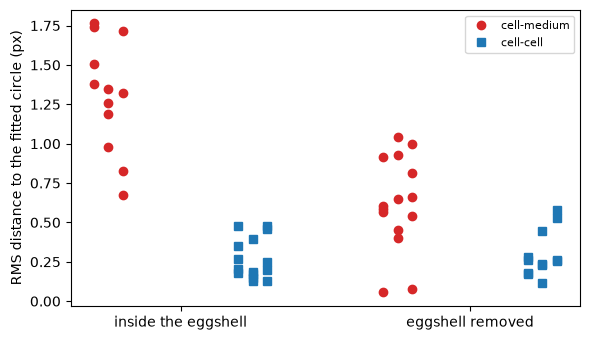

In [4]:
def distance_to_the_fitted_circles(mesh):
    """RMS distance (px) of each interface's vertices to its fitted circle, split into cell-medium and cell-cell."""
    points = np.asarray(mesh.points)
    medium, cell_cell = [], []
    for arc in foambryo.interface_arcs(mesh):
        if arc.fit != "circle":
            continue
        residual = np.hypot(*(points[list(arc.vertices)] - np.array(arc.centre)).T) - arc.radius
        (medium if 0 in arc.materials else cell_cell).append(float(np.sqrt(np.mean(residual**2))))
    return medium, cell_cell

fig, ax = plt.subplots(figsize=(6, 3.5))
for x0, (label, data) in enumerate([("inside the eggshell", confined), ("eggshell removed", free)]):
    for k in range(3):
        medium, cell_cell = distance_to_the_fitted_circles(foambryo.dcel_mesh_from_segmentation_mask(data["masks"][k]))
        ax.plot(np.full(len(medium), 2 * x0 + 0.1 * (k - 1)), medium, "o", color="C3", label="cell-medium" if x0 == 0 and k == 0 else None)
        ax.plot(np.full(len(cell_cell), 2 * x0 + 1 + 0.1 * (k - 1)), cell_cell, "s", color="C0", label="cell-cell" if x0 == 0 and k == 0 else None)
        print(f"{label:20s} frame {k}: cell-medium {np.round(medium, 2)}, cell-cell {np.round(cell_cell, 2)}")
ax.set_xticks([0.5, 2.5], ["inside the eggshell", "eggshell removed"])
ax.set_ylabel("RMS distance to the fitted circle (px)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Inside the eggshell the cell–medium interfaces depart from their fitted circle about twice as much as without it (in these three frames of one embryo each, 0.67 to 1.76 px against 0.06 to 1.04 px), while the cell–cell interfaces stay close to circles in both (0.12 to 0.58 px). A circle fitted to an interface flattened against the shell gives a wrong tangent at its ends and a wrong curvature, so the arc reading reads wrong junction angles at the cell–medium interfaces, the Laplace pressures read wrong curvatures, and the global fit, which forces every interface onto a circle and every cell to obey Laplace's law, has no way to represent the shell's push.

## The check, and what the readings that assume arcs give

`"fitted_tangent"` reads the tangent at the junction of a parabola through the junction and the next four vertices: like the chord it uses only the geometry near the junction, so it is the check of the chord. The arc reading and the global fit are computed here only to show how far they move from the local readings when their assumption fails.

interface            chord  fitted_tangent             arc      global fit
medium|EMS           1.174           1.039           0.814           0.496
medium|ABa           1.364           1.280           1.348           2.031
medium|ABp           1.330           1.157           1.055           0.508
medium|P2            1.145           1.006           0.990           0.846
EMS|ABa              0.506           0.617           0.908           1.711
EMS|ABp              0.699           0.838           0.900           0.228
EMS|P2               1.053           1.127           0.805           0.644
ABa|ABp              0.513           0.607           1.072           1.818
ABp|P2               1.217           1.329           1.110           0.717


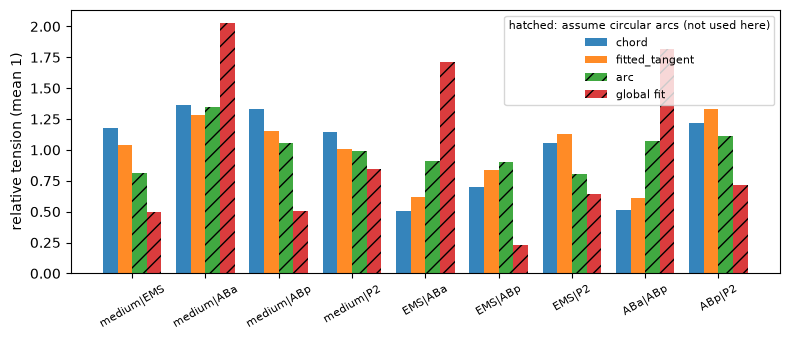

mean |chord - fitted_tangent| = 0.118
mean |chord - arc| = 0.258
mean |chord - global fit| = 0.706
chord           range 0.506 to 1.364
fitted_tangent  range 0.607 to 1.329
arc             range 0.805 to 1.348
global fit      range 0.228 to 2.031


In [5]:
readings = {"chord": tensions}
readings["fitted_tangent"] = foambryo.infer_tensions(mesh, angle_reading="fitted_tangent")
readings["arc"] = foambryo.infer_tensions(mesh, angle_reading="arc")
tiling, _, report = foambryo.infer_forces_by_equilibrium_tiling(mesh, mask, diagnostics=True)  # its pressures are not used
readings["global fit"] = tiling.dict_tensions

print(f"{'interface':10s}" + "".join(f"{r:>16s}" for r in readings))
for pair in pairs:
    print(f"{name_of(pair, names):10s}" + "".join(f"{readings[r][pair]:16.3f}" for r in readings))

fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.2
for i, reading in enumerate(readings):
    ax.bar(np.arange(len(pairs)) + (i - 1.5) * width, [readings[reading][p] for p in pairs], width, label=reading,
           hatch="//" if reading in ("arc", "global fit") else None, alpha=0.9)
ax.set_xticks(np.arange(len(pairs)), [name_of(p, names) for p in pairs], rotation=30, fontsize=8)
ax.set_ylabel("relative tension (mean 1)")
ax.legend(fontsize=8, title="hatched: assume circular arcs (not used here)", title_fontsize=8)
plt.tight_layout()
plt.show()

def mean_difference(a, b):
    return np.mean([abs(readings[a][p] - readings[b][p]) for p in pairs])

for other in ("fitted_tangent", "arc", "global fit"):
    print(f"mean |chord - {other}| = {mean_difference('chord', other):.3f}")
for reading in readings:
    values = [readings[reading][p] for p in pairs]
    print(f"{reading:15s} range {min(values):.3f} to {max(values):.3f}")

On this frame the chord and the fitted tangent differ by 0.118 on average; the arc reading moves 0.258 from the chord, and the global fit 0.706, its tensions spreading from 0.228 to 2.031 against 0.506 to 1.364 for the chord. No real image has known tensions, so this cannot say which local reading is closer to the truth; it shows that the readings which assume circular interfaces depart from the local ones exactly where the shell flattens the interfaces.

## The deviatoric stress: the cortical tensions' contribution

The full stress of a cell, $\sigma = -p\,I + \frac{1}{A}\sum_m \gamma_m \sum_e l_e\, \mathbf{t}_e \mathbf{t}_e^\top$, contains the pressure, so it is not a measurement here. Its **deviatoric part**, $\sigma - \frac{\operatorname{tr}\sigma}{2} I$, does not contain it: it is computed from the tensions and the cell's boundary alone, and is the contribution of the cortical tensions to the cell's stress anisotropy. Inside the eggshell the shell's contact forces also act on the cells and are not in it: it is not the cell's total stress anisotropy. `plot_force_inference(..., stress="deviatoric")` draws it (principal axes scaled by their values; compression red, tension teal), with its own colour bar and without colouring the cells by pressure; given no pressures, the viewer infers them only for the full-stress option of its panel.

[polyscope] Backend: openGL3_glfw -- Loaded openGL version: 4.1 Metal - 91.7


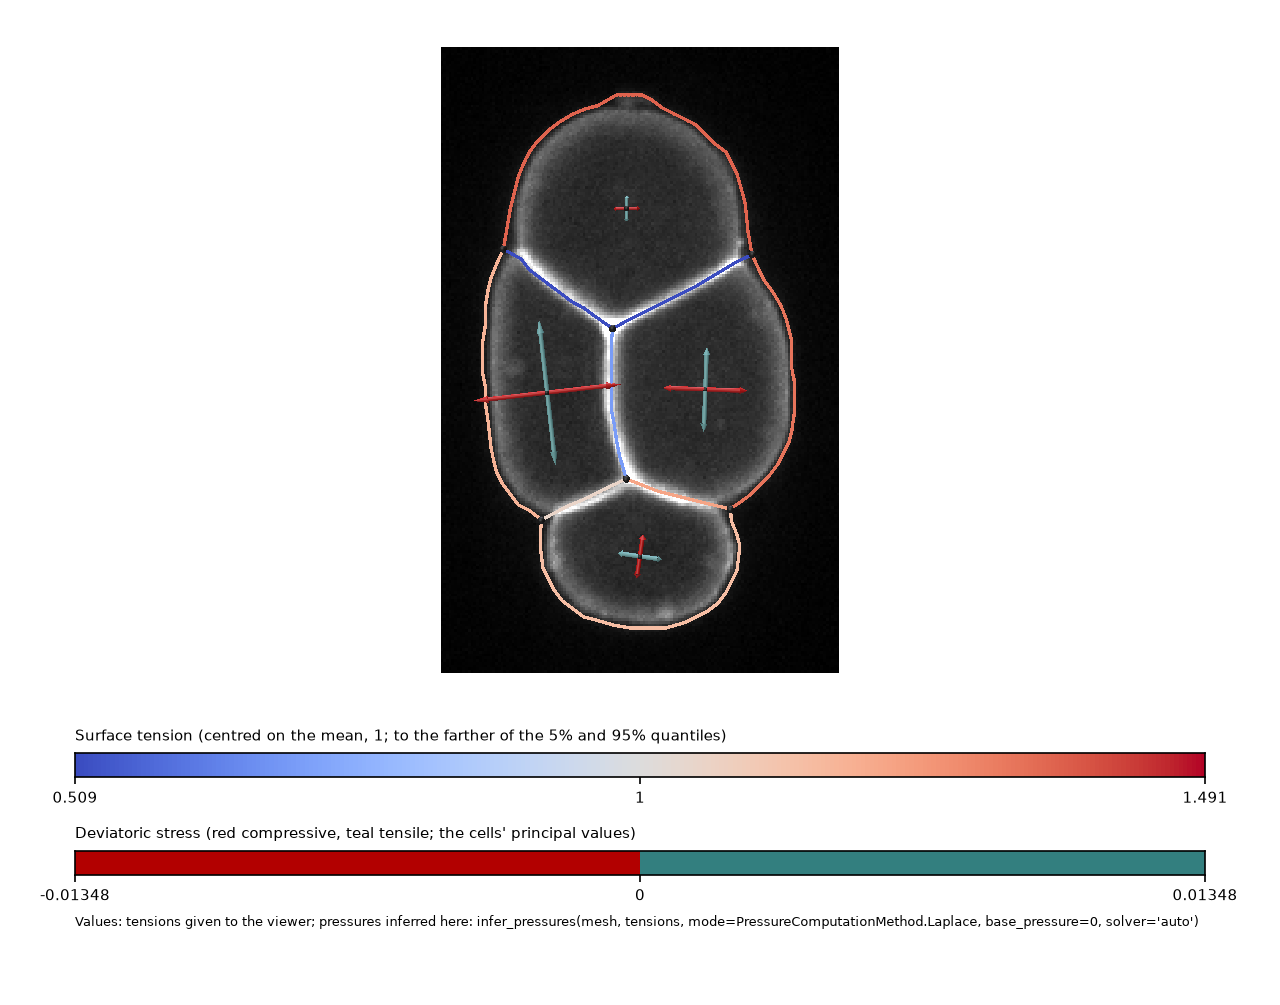

In [6]:
figure = FIGURES / "embryo_in_its_eggshell_deviatoric_stress.png"
plot_force_inference(mesh, tensions, image=image, stress="deviatoric", angle_reading="chord", save_figure=figure, show=False)
display(Image(filename=figure, width=700))

## In short

| tissue | junction angles | tensions | pressures and full stress | deviatoric stress |
|---|---|---|---|---|
| free, near equilibrium (no eggshell, no substrate) | `"arc"` (default); the global fit, opt-in | yes | yes | the anisotropic part of the cell's stress |
| compressed or confined (eggshell, substrate) | `"chord"`; `"fitted_tangent"` as a check | yes, read near the junctions | no | the cortical tensions' contribution only |

On the command line: `foambryo infer MESH --angle-reading chord --no-pressures`, and `foambryo view MESH --angle-reading chord --stress deviatoric`. For a free embryo, whether the arc or the chord is closer to the truth on real masks is an open question (see the free-tissue example).